# 03 · Target multi-label dan Morgan 2048 + 8

**File:** `03_Dataset_dan_Fitur.ipynb`

Tujuan: melihat bentuk X dan y aktual, urutan 109 target, dan hasil perhitungan fitur seluruh molekul dibandingkan artefak penelitian.

**Urutan belajar:** 02_Preprocessing_dan_Audit_Label.ipynb → notebook ini → 04_Grup_Split_dan_Fold.ipynb.

**Mode:** penelusuran implementasi dan pemeriksaan data di memori. Run All tidak melatih model, tidak mengunduh data, dan tidak menimpa hasil penelitian. Setiap notebook membaca inputnya sendiri; tidak memerlukan variabel dari notebook lain.

Kode ML hanya memiliki satu sumber di `KODE_ML/research/`. Sel tampilan source membaca fungsi yang benar-benar diimpor; output kode itu bukan implementasi kedua. Sel berikutnya memanggil fungsi tersebut. Data/model besar tetap di folder artefak proyek.

## Persiapan
Cari folder KODE_ML dari lokasi notebook. Import mengambil kode lokal dan menampilkan lokasi aktual supaya asal kode dapat diperiksa.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
cari = [Path.cwd(), *Path.cwd().parents]
KODE = next((p if (p / "research/runtime.py").is_file() and p.name == "KODE_ML"
             else p / "KODE_ML" for p in cari
             if (p / "research/runtime.py").is_file() and p.name == "KODE_ML"
             or (p / "KODE_ML/research/runtime.py").is_file()), None)
if KODE is None:
    raise FileNotFoundError("Buka notebook dari folder proyek atau KODE_ML.")
sys.path.insert(0, str(KODE))
from research.runtime import ROOT, read, digest
from belajar import tampilkan_sumber, tampilkan_awal
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 85)
print("Kode aktif:", KODE)


Kode aktif: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML


## Kode fitur aktual

NumPy menyimpan matriks; RDKit membuat fingerprint dan delapan deskriptor. Nama deskriptor dan urutan fitur adalah bagian kontrak model.

In [2]:
from research import features as feat, dataset
tampilkan_awal(feat)

**Import dan konstanta aktual:** `KODE_ML/research/features.py`. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
"""SMILES -> Morgan 2048 dan delapan angka deskriptor, dengan urutan tetap."""
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from .runtime import ROOT
N_BITS = 2048
RADIUS = 2
DESCRIPTORS8 = ("MolWt", "MolLogP", "NumHDonors", "NumHAcceptors", "TPSA", "NumRotatableBonds", "HeavyAtomCount", "RingCount")
EXTRA = ROOT / "data/builds/perfume-m2048-d8-v7"
CANDIDATES = tuple(f"{algorithm}_{condition}" for algorithm in ("xgb", "lgbm") for condition in "ABCD")

```

## molecule

Input SMILES dan indeks baris; output molekul RDKit valid satu komponen. Tidak boleh ada baris yang diam-diam dibuang pada tahap fitur.

In [3]:
tampilkan_sumber(feat.molecule)

**Source aktual:** `KODE_ML/research/features.py`, baris 12–16. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def molecule(smiles, index):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError(f"Invalid or multicomponent structure at row {index}; no rows may be dropped.")
    return mol

```

## calculate_morgan

Generator radius=2, fpSize=2048, includeChirality=False dibuat sekali, lalu dipakai untuk semua molekul. Bit menandai pola substruktur, bukan konversi teks SMILES ke biner.

In [4]:
tampilkan_sumber(feat.calculate_morgan)

**Source aktual:** `KODE_ML/research/features.py`, baris 29–33. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def calculate_morgan(smiles):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=RADIUS, fpSize=N_BITS, includeChirality=False)
    return np.asarray([generator.GetFingerprintAsNumPy(molecule(smi, i))
                       for i, smi in enumerate(smiles)], dtype=np.uint8)

```

## calculate

Delapan fungsi RDKit dijalankan pada setiap molekul dan ditaruh pada urutan DESCRIPTORS8. Output float32, bukan delapan bit. Nilai nonfinite dianggap error, tidak diimputasi.

In [5]:
tampilkan_sumber(feat.calculate)

**Source aktual:** `KODE_ML/research/features.py`, baris 19–26. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def calculate(smiles):
    values = np.empty((len(smiles), 8), dtype=np.float32)
    for i, value in enumerate(smiles):
        mol = molecule(value, i)
        values[i] = [getattr(Descriptors, name)(mol) for name in DESCRIPTORS8]
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite descriptors; no silent imputation.")
    return values

```

## descriptor_count

A/C memakai Morgan saja; B/D memakai semua delapan deskriptor. Tidak memilih deskriptor berdasarkan data test.

In [6]:
tampilkan_sumber(feat.descriptor_count)

**Source aktual:** `KODE_ML/research/features.py`, baris 35–38. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def descriptor_count(key):
    if key not in CANDIDATES:
        raise ValueError(f"Unknown candidate: {key}")
    return 8 if key[-1] in "BD" else 0

```

## features

Menggabungkan kolom Morgan dan deskriptor sesuai kandidat. Seluruh X menjadi float32 untuk estimator; urutan kolom selalu sama.

In [7]:
tampilkan_sumber(feat.features)

**Source aktual:** `KODE_ML/research/features.py`, baris 41–45. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def features(key, morgan, descriptors):
    if (morgan.ndim != 2 or morgan.shape[1] != N_BITS or descriptors.shape != (len(morgan), 8)
            or not np.isfinite(descriptors).all()):
        raise ValueError("Expected Morgan 2048 and eight ordered descriptors per molecular row.")
    return np.column_stack([morgan, descriptors[:, :descriptor_count(key)]]).astype(np.float32)

```

## verify

Penghubung ke pemeriksaan dataset dan bundle fitur aktual.

| Blok pemeriksaan | Input → hasil |
|---|---|
| contract + dua manifest | Bandingkan hash file; isi yang berubah memicu error. |
| records, labels, groups | Periksa identitas/urutan, SMILES unik, registry target dan asal grup. |
| validate_grouped_split | Pastikan indeks/grup tidak tumpang tindih antara partisi yang dibandingkan. |
| feature_spec + features.npz | Periksa 2048 bit, radius 2, chirality False, urutan delapan deskriptor dan baris. |
| shape/dtype/value | Morgan harus uint8 0/1; deskriptor float32 finite. |
| train/test NPZ | Periksa indeks dan sumber baris; saat preflight hanya truth train yang didekode. |
| posisi dan fold | Setiap train/validation fold wajib punya kelas 0 dan 1. |
| recompute=True | Hitung ulang semua fitur 2048+8 dan bandingkan persis dengan arsip. |
| return | Kembalikan metadata fitur aktual di memori; tidak menulis ulang manifest historis. |


In [8]:
tampilkan_sumber(feat.verify)

**Source aktual:** `KODE_ML/research/features.py`, baris 47–50. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0`.

```python
def verify(dataset=None, extra=EXTRA):
    from .dataset import DATASET, verify as verify_dataset
    _, _, meta, morgan, descriptors = verify_dataset(DATASET if dataset is None else dataset, extra)
    return meta, morgan, descriptors

```

## verify

Memeriksa SHA, baris, label, grup, split, jenis data dan skema fitur. recompute=True menghitung Morgan2048+8 seluruh molekul dan mengecek kesamaan persis. Saat preflight, label test tidak didekode.

| Blok pemeriksaan | Input → hasil |
|---|---|
| contract + dua manifest | Bandingkan hash file; isi yang berubah memicu error. |
| records, labels, groups | Periksa identitas/urutan, SMILES unik, registry target dan asal grup. |
| validate_grouped_split | Pastikan indeks/grup tidak tumpang tindih antara partisi yang dibandingkan. |
| feature_spec + features.npz | Periksa 2048 bit, radius 2, chirality False, urutan delapan deskriptor dan baris. |
| shape/dtype/value | Morgan harus uint8 0/1; deskriptor float32 finite. |
| train/test NPZ | Periksa indeks dan sumber baris; saat preflight hanya truth train yang didekode. |
| posisi dan fold | Setiap train/validation fold wajib punya kelas 0 dan 1. |
| recompute=True | Hitung ulang semua fitur 2048+8 dan bandingkan persis dengan arsip. |
| return | Kembalikan metadata fitur aktual di memori; tidak menulis ulang manifest historis. |


In [9]:
tampilkan_sumber(dataset.verify)

**Source aktual:** `KODE_ML/research/dataset.py`, baris 14–79. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8dc2ecbc33f556fd0f4b1b655fe8c728de1ccc141bfc1af7b6fd45781b2caeb3`.

```python
def verify(dataset=DATASET, extra=EXTRA, *, recompute=False):
    """Periksa identitas beku; recompute hanya menghitung ulang fitur 2048+8."""
    dataset, extra = Path(dataset), Path(extra)
    contract = read(CONFIG)
    for folder, entries in ((dataset, contract["dataset_files"]), (extra, contract["feature_files"])):
        for name, expected in entries.items():
            if digest(folder / name) != expected:
                raise ValueError(f"Frozen input changed: {folder / name}")
    meta = read(dataset / "dataset_manifest.json")
    split = read(dataset / "splits.json")
    feature_meta = read(extra / "manifest.json")
    for folder, manifest in ((dataset, meta), (extra, feature_meta)):
        for name, expected in manifest["files"].items():
            if digest(folder / name) != expected:
                raise ValueError(f"Original provenance hash changed: {name}")
    records = pd.read_csv(dataset / "records.csv")
    stored_groups = pd.read_csv(dataset / "groups.csv")
    labels = meta["labels"]
    if (len(records) != contract["rows"] or len(labels) != contract["label_count"]
            or len(set(labels)) != len(labels) or labels != split["eligible_labels"]
            or meta["group_policy"] != POLICY or records.smiles.isna().any()
            or records.smiles.duplicated().any()):
        raise ValueError("Frozen cohort or label registry changed.")
    if (stored_groups.smiles.tolist() != records.smiles.tolist()
            or stored_groups.source_row.tolist() != records.source_row.tolist()):
        raise ValueError("Group row identity differs from the molecular records.")
    validate_grouped_split(split, stored_groups.group_id.to_numpy())
    if feature_meta["dataset_manifest_sha256"] != digest(dataset / "dataset_manifest.json"):
        raise ValueError("Feature bundle belongs to another cohort.")
    spec = feature_meta["feature_spec"]
    if (spec["n_bits"] != N_BITS or spec["radius"] != 2
            or spec["include_chirality"] is not False or spec["descriptors"] != list(DESCRIPTORS8)):
        raise ValueError("Expected the main 2048+8 feature schema.")
    with np.load(extra / "features.npz", allow_pickle=False) as z:
        morgan, descriptors = z["morgan"], z["descriptors"]
        if (z["row_index"].tolist() != list(range(len(records)))
                or z["source_row"].tolist() != records.source_row.tolist()
                or z["names"].tolist() != list(DESCRIPTORS8)):
            raise ValueError("Feature order or molecular identity changed.")
    if (morgan.shape != (len(records), N_BITS) or morgan.dtype != np.uint8
            or descriptors.shape != (len(records), 8) or descriptors.dtype != np.float32
            or not np.isin(morgan, [0, 1]).all() or not np.isfinite(descriptors).all()):
        raise ValueError("Invalid feature values or dimensions.")
    for role in ("train", "test"):
        # Test labels are not decoded during preflight; file bytes are only hashed above.
        with np.load(dataset / f"{role}.npz", allow_pickle=False) as z:
            if (z["row_index"].tolist() != split[role]
                    or z["source_row"].tolist() != records.source_row.to_numpy()[split[role]].tolist()
                    or len(split[role]) != contract[f"{role}_rows"]):
                raise ValueError(f"{role}: frozen row order changed.")
            if role == "train":
                target = z["truth"]
                if target.shape != (len(split[role]), len(labels)) or not np.isin(target, [0, 1]).all():
                    raise ValueError("Invalid training target matrix.")
    positions = {row: i for i, row in enumerate(split["train"])}
    for j, name in enumerate(labels):
        for fold in split["folds"][name]:
            for part in ("train", "validation"):
                if np.unique(target[[positions[i] for i in fold[part]], j]).size != 2:
                    raise ValueError(f"Fold for {name} lacks one target class.")
    if recompute:
        smiles = records.smiles.tolist()
        if not np.array_equal(calculate_morgan(smiles), morgan) or not np.array_equal(calculate(smiles), descriptors):
            raise ValueError("2048+8 values differ from recomputed molecular features.")
    # The old manifest remains untouched. Return an in-memory view with actual model features.
    return dict(meta, feature_spec=spec), split, feature_meta, morgan, descriptors

```

## load_partition

Mengambil truth dan indeks dari kohor beku; X berasal dari bundle fitur 2048+8 pada indeks yang sama. Array fitur lama yang masih tersimpan di NPZ kohor tidak digunakan untuk training utama.

In [10]:
tampilkan_sumber(dataset.load_partition)

**Source aktual:** `KODE_ML/research/dataset.py`, baris 82–93. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8dc2ecbc33f556fd0f4b1b655fe8c728de1ccc141bfc1af7b6fd45781b2caeb3`.

```python
def load_partition(role, dataset=DATASET, extra=EXTRA, *, verified=None):
    if role not in ("train", "test"):
        raise ValueError("Partition must be train or test.")
    meta, split, _, morgan, descriptors = verified or verify(dataset, extra)
    with np.load(Path(dataset) / f"{role}.npz", allow_pickle=False) as z:
        result = {key: z[key].copy() for key in ("row_index", "source_row", "truth")}
    rows = result["row_index"]
    if (rows.tolist() != split[role] or result["truth"].shape != (len(rows), len(meta["labels"]))
            or not np.isin(result["truth"], [0, 1]).all()):
        raise ValueError("Partition target or row order changed.")
    result.update(morgan=morgan[rows], descriptors=descriptors[rows])
    return result

```

## encode_frozen_records

Untuk audit: records hasil cleaning harus sama persis dengan records beku. Label dipetakan ke urutan registry yang sudah dipilih pada pembentukan kohor. Angka 0 berarti label tidak tercatat, bukan bukti pasti aroma tidak ada.

In [11]:
tampilkan_sumber(dataset.encode_frozen_records)

**Source aktual:** `KODE_ML/research/dataset.py`, baris 96–109. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `8dc2ecbc33f556fd0f4b1b655fe8c728de1ccc141bfc1af7b6fd45781b2caeb3`.

```python
def encode_frozen_records(records, dataset=DATASET, *, verified=None):
    """Encode labels with the frozen registry; never select new labels or shuffle rows."""
    meta, split, _, _, _ = verified or verify(dataset)
    original = pd.read_csv(Path(dataset) / "records.csv")
    for name in ("labels", "sources"):
        original[name] = original[name].map(json.loads)
    pd.testing.assert_frame_equal(records.reset_index(drop=True), original, check_dtype=True)
    target = np.asarray([[int(name in row) for name in meta["labels"]]
                         for row in records.labels], dtype=np.uint8)
    for role in ("train", "test"):
        with np.load(Path(dataset) / f"{role}.npz", allow_pickle=False) as z:
            if not np.array_equal(target[split[role]], z["truth"]):
                raise ValueError("Encoded labels differ from frozen targets.")
    return target, meta["labels"], split

```

## Hitung ulang fitur dan cek seluruh baris

Ini perhitungan fitur ringan, bukan training. Input: 6.686 SMILES yang sudah dibekukan. Output: matriks fitur beserta verifikasi kesamaan persis dengan nilai yang dipakai penelitian.

In [12]:
verified = dataset.verify(recompute=True)
meta, split, feature_meta, morgan, descriptors = verified
train = dataset.load_partition('train', verified=verified)
test = dataset.load_partition('test', verified=verified)
display(pd.DataFrame([{'bagian':role,'baris':len(part['truth']),'target':part['truth'].shape[1],
 'Morgan':part['morgan'].shape[1],'deskriptor':part['descriptors'].shape[1]}
 for role,part in [('train',train),('test',test)]]))
print('Fitur seluruh kohor identik:', morgan.shape, descriptors.shape)
display(pd.DataFrame({'kolom_target':range(len(meta['labels'])),'label':meta['labels']}).head(12))

,bagian,baris,target,Morgan,deskriptor
0,train,5353,109,2048,8
1,test,1333,109,2048,8


Fitur seluruh kohor identik: (6686, 2048) (6686, 8)


,kolom_target,label
0,0,acidic
1,1,aldehydic
2,2,almond
3,3,amber
4,4,animal like
5,5,anisic
6,6,apple
7,7,apricot
8,8,aromatic
9,9,balsamic


## Lihat satu molekul yang memang ada dalam data

Output tabel deskriptor menunjukkan angka fisik/struktur, sementara potongan Morgan berisi 0/1. Hanya label positif ditampilkan agar mudah dibaca; matriks target tetap 109 kolom.

In [13]:
records = pd.read_csv(dataset.DATASET/'records.csv')
i = split['train'][0]
print('SMILES:', records.iloc[i].smiles)
display(pd.DataFrame({'deskriptor':feat.DESCRIPTORS8,'nilai':descriptors[i]}))
print('32 bit pertama:', morgan[i,:32].tolist())
print('Jumlah bit aktif:', int(morgan[i].sum()))
print('Label tercatat pada 109 target:', np.asarray(meta['labels'])[train['truth'][0].astype(bool)].tolist())
display(pd.DataFrame([{'kandidat':k,'shape_X_train':str(feat.features(k,train['morgan'],train['descriptors']).shape)} for k in feat.CANDIDATES]))

SMILES: BrC=Cc1ccccc1


,deskriptor,nilai
0,MolWt,183.048004
1,MolLogP,3.052200
2,NumHDonors,0.000000
3,NumHAcceptors,0.000000
4,TPSA,0.000000
5,NumRotatableBonds,1.000000
6,HeavyAtomCount,9.000000
7,RingCount,1.000000


32 bit pertama: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Jumlah bit aktif: 15
Label tercatat pada 109 target: ['floral', 'green', 'hyacinth', 'leafy']


,kandidat,shape_X_train
0,xgb_A,"(5353, 2048)"
1,xgb_B,"(5353, 2056)"
2,xgb_C,"(5353, 2048)"
3,xgb_D,"(5353, 2056)"
4,lgbm_A,"(5353, 2048)"
5,lgbm_B,"(5353, 2056)"
6,lgbm_C,"(5353, 2048)"
7,lgbm_D,"(5353, 2056)"


## Sebaran dukungan label di training

Grafik memakai jumlah molekul positif per label pada training saja. Preview 20 terbesar tidak mengubah jumlah target model.

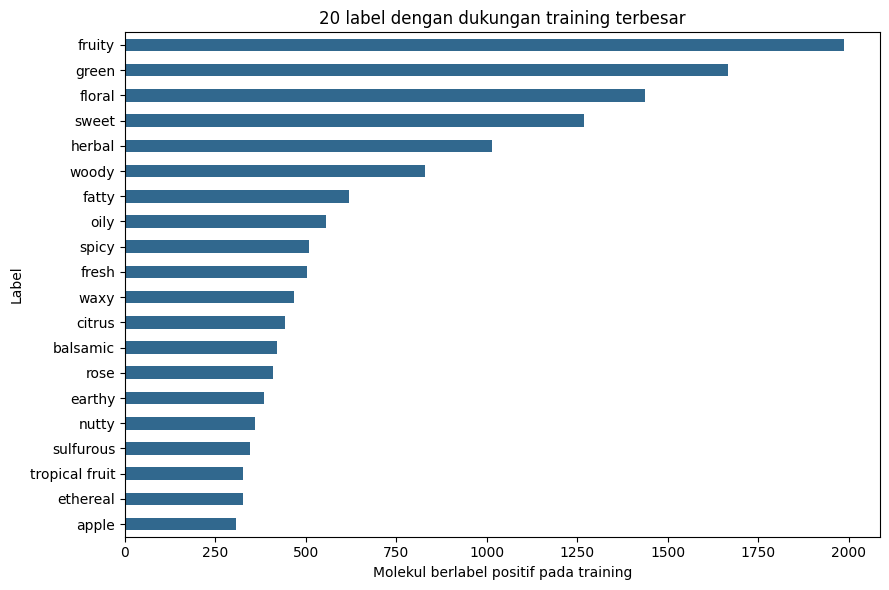

,dukungan_training
count,109.000000
mean,209.284404
std,320.722393
min,32.000000
25%,63.000000
50%,100.000000
75%,165.000000
max,1987.000000


In [14]:
import matplotlib.pyplot as plt
support = pd.Series(train['truth'].sum(axis=0),index=meta['labels']).sort_values()
fig,ax=plt.subplots(figsize=(9,6))
support.tail(20).plot.barh(ax=ax,color='#31688e')
ax.set(xlabel='Molekul berlabel positif pada training',ylabel='Label',title='20 label dengan dukungan training terbesar')
fig.tight_layout();plt.show()
display(support.describe().to_frame('dukungan_training'))

Frekuensi label tidak seimbang. Setiap molekul boleh memiliki beberapa label, jadi jumlah positif lintas label bukan jumlah molekul unik.

## Cek pemahaman
X adalah angka 2048 atau 2056 kolom. y adalah 109 kolom 0/1. Urutan X dan y harus konsisten sejak training sampai prediksi. Fitur yang sama tidak menjamin dua molekul identik; fingerprint memiliki benturan hash.